# 03 - BiLSTM (E3, E4)

TF-IDF only counts words, it doesn't know their order. An LSTM reads the tweet word by word and keeps
a memory, so it can (in theory) pick up things like "no be say i no like am".

- **E3** BiLSTM with embeddings learned from scratch (random start)
- **E4** same BiLSTM, but the embeddings start from Word2Vec trained on the training tweets

Both use class weights in the loss because that helped the baselines. Small data makes neural nets
jumpy, so each experiment is run with 3 seeds and I report the mean and std.

In [1]:
import sys
import random
import collections

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from gensim.models import Word2Vec
from sklearn.utils.class_weight import compute_class_weight

sys.path.append("../src")
from preprocess import LABELS, LABEL2ID
from metrics import get_scores, print_report, plot_confusion, log_result

train = pd.read_csv("../data/processed/train.csv")
dev = pd.read_csv("../data/processed/dev.csv")
test_official = pd.read_csv("../data/processed/test_official.csv")
test_clean = pd.read_csv("../data/processed/test_clean.csv")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Vocabulary and turning tweets into numbers

Each word gets an id. Words seen less than 2 times in train become `<unk>` (unknown), because one
example is not enough to learn anything about a word. `<pad>` fills short tweets up to the same length.

In [2]:
MAX_LEN = 64
MIN_FREQ = 2

counts = collections.Counter(w for t in train["text"] for w in t.split())
vocab = ["<pad>", "<unk>"] + [w for w, n in counts.items() if n >= MIN_FREQ]
word2id = {w: i for i, w in enumerate(vocab)}
print("vocab size:", len(vocab))


def encode(text):
    ids = [word2id.get(w, 1) for w in text.split()][:MAX_LEN]
    return ids + [0] * (MAX_LEN - len(ids))


def make_loader(df, shuffle, batch_size=32):
    x = torch.tensor([encode(t) for t in df["text"]])
    y = torch.tensor([LABEL2ID[l] for l in df["label"]])
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle)


unk_rate = np.mean([word2id.get(w, 1) == 1 for t in test_clean["text"] for w in t.split()])
print(f"unknown words in clean test: {unk_rate:.1%}")
print(train["text"][0])
print(encode(train["text"][0])[:20])

vocab size: 4417
unknown words in clean test: 8.5%
this life is so funny sef you will work hard and buy cloths and shoes and rain will start dictating when to wear them for you because you see rain to wear white na war to wear suede na wahala shoe wey i take my money buy
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 1, 12, 14, 12, 15, 9, 16, 1]


## The model

embedding -> bidirectional LSTM -> join the last hidden state of both directions -> dropout -> linear
layer giving 3 scores (one per class).

In [3]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=100, hidden_dim=64, n_classes=3, dropout=0.5, pretrained=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        if pretrained is not None:
            self.embedding.weight.data.copy_(torch.tensor(pretrained))
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        emb = self.embedding(x)
        # packing tells the lstm where each tweet really ends, so it doesn't read the padding
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        # hidden[-2] = last state going forward, hidden[-1] = last state going backward
        h = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.fc(self.dropout(h))


BiLSTMClassifier(len(vocab))

BiLSTMClassifier(
  (embedding): Embedding(4417, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)

## Training loop

- loss: cross entropy with class weights (rare classes cost more when wrong)
- optimizer: Adam, lr 1e-3
- early stopping: keep the epoch with the best dev macro-F1, stop if no improvement for 3 epochs

In [4]:
weights = compute_class_weight("balanced", classes=np.array(LABELS), y=train["label"])
class_weights = torch.tensor(weights, dtype=torch.float).to(device)
print(dict(zip(LABELS, weights.round(2))))

train_loader = make_loader(train, shuffle=True)
eval_loaders = {"dev": make_loader(dev, False), "test_official": make_loader(test_official, False),
                "test_clean": make_loader(test_clean, False)}
eval_dfs = {"dev": dev, "test_official": test_official, "test_clean": test_clean}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in loader:
            preds += model(x.to(device)).argmax(dim=1).tolist()
    return [LABELS[p] for p in preds]


def train_model(pretrained=None, seed=42, epochs=20, patience=3, lr=1e-3):
    set_seed(seed)
    model = BiLSTMClassifier(len(vocab), pretrained=pretrained).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    best_f1, best_state, bad_epochs, history = -1, None, 0, []

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)

        dev_f1 = get_scores(dev["label"], predict(model, eval_loaders["dev"]))["macro_f1"]
        history.append({"epoch": epoch, "train_loss": total_loss / len(train), "dev_macro_f1": dev_f1})
        if dev_f1 > best_f1:
            best_f1, bad_epochs = dev_f1, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

{'negative': np.float64(0.51), 'neutral': np.float64(23.12), 'positive': np.float64(0.99)}


## E3 - random embeddings

In [5]:
SEEDS = [42, 1, 7]


def run_experiment(exp_id, name, pretrained=None):
    all_scores, models = [], []
    for seed in SEEDS:
        model, history = train_model(pretrained=pretrained, seed=seed)
        best_epoch = history.loc[history["dev_macro_f1"].idxmax(), "epoch"]
        print(f"seed {seed}: best epoch {best_epoch}, dev macro-F1 {history['dev_macro_f1'].max():.4f}")
        for split, loader in eval_loaders.items():
            scores = get_scores(eval_dfs[split]["label"], predict(model, loader))
            all_scores.append({"seed": seed, "split": split, **scores})
        models.append((model, history))

    all_scores = pd.DataFrame(all_scores)
    mean = all_scores.drop(columns="seed").groupby("split").mean().round(4)
    std = all_scores.drop(columns="seed").groupby("split").std().round(4)
    for split in eval_loaders:
        log_result(exp_id, name, split, mean.loc[split].to_dict(),
                   f"mean of seeds {SEEDS}, macro_f1 std={std.loc[split, 'macro_f1']}")
    return all_scores, mean, std, models


e3_scores, e3_mean, e3_std, e3_models = run_experiment("E3", "bilstm random embeddings")
e3_mean

seed 42: best epoch 6, dev macro-F1 0.4013


seed 1: best epoch 11, dev macro-F1 0.4123


seed 7: best epoch 9, dev macro-F1 0.3949


,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
split,,,,,,
dev,0.6315,0.4028,0.6295,0.7161,0.0000,0.4924
test_clean,0.5445,0.3834,0.5080,0.6441,0.0187,0.4873
test_official,0.6071,0.4235,0.5783,0.6982,0.0223,0.5501


In [6]:
# learning curve of the first seed: loss keeps going down but dev f1 stops improving = overfitting
e3_models[0][1]

,epoch,train_loss,dev_macro_f1
0,1,1.067481,0.3317
1,2,0.997371,0.3611
2,3,0.863055,0.3663
3,4,0.692898,0.3749
4,5,0.586118,0.3726
5,6,0.488088,0.4013
6,7,0.446323,0.4003
7,8,0.363097,0.3970
8,9,0.315377,0.3941


## E4 - Word2Vec embeddings

Word2Vec (skip-gram) learns a vector for each word by predicting the words around it. I train it on
the training tweets only, so no dev or test text leaks in.

In [7]:
sentences = [t.split() for t in train["text"]]
w2v = Word2Vec(sentences, vector_size=100, window=5, min_count=MIN_FREQ, sg=1, epochs=30, seed=42, workers=1)

# sanity check: do spelling variants end up close to each other?
for w in ["dey", "this", "wahala", "vex", "sweet"]:
    if w in w2v.wv:
        print(w, "->", [x for x, _ in w2v.wv.most_similar(w, topn=6)])

dey -> ['omoh', 'microphone', 'secondary', 'iswear', 'mugu', 'dressing']
this -> ['beside', 'punch', 'princess', 'content', 'wenger', 'bird']
wahala -> ['bicycle', 'flag', 'weds', 'stray', 'occur', 'coro']
vex -> ['lasisi', 'miracle', 'content', 'pam', 'brilliant', 'flog']
sweet -> ['convulse', 'tagged', 'third', 'middle', 'shape', 'mena']


In [8]:
# build the embedding matrix in the same order as my vocab
rng = np.random.default_rng(42)
embedding_matrix = rng.normal(0, 0.1, (len(vocab), 100)).astype("float32")
embedding_matrix[0] = 0  # padding stays zero
found = 0
for word, i in word2id.items():
    if word in w2v.wv:
        embedding_matrix[i] = w2v.wv[word]
        found += 1
print(f"{found} of {len(vocab)} words got a word2vec vector")

4415 of 4417 words got a word2vec vector


In [9]:
e4_scores, e4_mean, e4_std, e4_models = run_experiment("E4", "bilstm word2vec embeddings", pretrained=embedding_matrix)
e4_mean

seed 42: best epoch 7, dev macro-F1 0.4245


seed 1: best epoch 5, dev macro-F1 0.4178


seed 7: best epoch 2, dev macro-F1 0.4153


,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
split,,,,,,
dev,0.6556,0.4192,0.6545,0.7498,0.0065,0.5014
test_clean,0.5740,0.4030,0.5346,0.6857,0.0249,0.4984
test_official,0.6256,0.4345,0.5950,0.7270,0.0253,0.5511


## Comparison

In [10]:
compare = pd.DataFrame({
    "E3 mean": e3_mean["macro_f1"], "E3 std": e3_std["macro_f1"],
    "E4 mean": e4_mean["macro_f1"], "E4 std": e4_std["macro_f1"],
})
compare

,E3 mean,E3 std,E4 mean,E4 std
split,,,,
dev,0.4028,0.0088,0.4192,0.0048
test_clean,0.3834,0.0024,0.4030,0.0100
test_official,0.4235,0.0075,0.4345,0.0162


              precision    recall  f1-score   support

    negative      0.625     0.787     0.697      1708
     neutral      0.043     0.005     0.008       429
    positive      0.523     0.494     0.508      1091

    accuracy                          0.584      3228
   macro avg      0.397     0.429     0.404      3228
weighted avg      0.513     0.584     0.541      3228



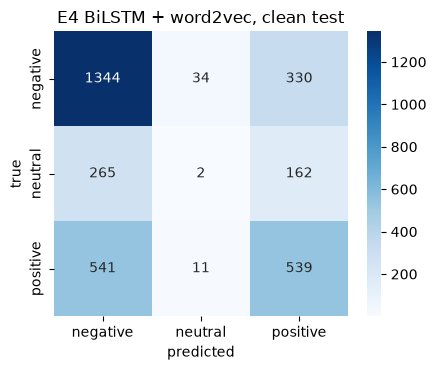

In [11]:
# confusion matrix of the best single E4 run on the clean test
best_idx = e4_scores[e4_scores["split"] == "dev"]["macro_f1"].values.argmax()
best_model = e4_models[best_idx][0]
pred = predict(best_model, eval_loaders["test_clean"])
print_report(test_clean["label"], pred)
plot_confusion(test_clean["label"], pred, "E4 BiLSTM + word2vec, clean test", "confusion_E4_test_clean.png")